# Agrupar y sacar promedio

Registros web de ejemplo — María Ignacia Parra

Agrupa registros por código de respuesta HTTP y compara el promedio de bytes por grupo.

[Volver al índice](00_indice.ipynb)

## 1. Conexión

En Kibana (`http://localhost:5601`), la consola de Dev Tools envía peticiones a Elasticsearch. Python hace la misma petición directamente, sin pasar por Kibana: desde Jupyter en Docker Compose, `elasticsearch` es el nombre del servicio y `9200` su puerto. Si el kernel corre en el equipo anfitrión, usa `http://localhost:9200`.

El índice de ejemplo debe existir antes de ejecutar la consulta. Este cuaderno no instala datos ni modifica el clúster.

In [1]:
import json
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt

url_elasticsearch = "http://elasticsearch:9200"

## 2. Configuración

En `kibana_sample_data_logs`, `terms` agrupa por el valor exacto de `response.keyword` y devuelve hasta cinco códigos, ordenados por cantidad de registros. Dentro de cada grupo, `avg` promedia el campo numérico `bytes` e ignora registros sin ese valor. El `size: 0` superior omite los documentos individuales.

Edita estos valores para cambiar la consulta de Python.

In [2]:
indice = "kibana_sample_data_logs"
campo_grupo = "response.keyword"
campo_promedio = "bytes"
limite_grupos = 5

cuerpo = {
    "size": 0,
    "aggs": {
        "por_codigo": {
            "terms": {"field": campo_grupo, "size": limite_grupos},
            "aggs": {"promedio_bytes": {"avg": {"field": campo_promedio}}},
        }
    },
}

## 3. Ejecución

Copiar el bloque entero en la consola de Dev Tools para ejecutar la consulta con los valores predeterminados.

```http
GET kibana_sample_data_logs/_search
{
  "size": 0,
  "aggs": {
    "por_codigo": {
      "terms": {
        "field": "response.keyword",
        "size": 5
      },
      "aggs": {
        "promedio_bytes": {
          "avg": {
            "field": "bytes"
          }
        }
      }
    }
  }
}
```

En Jupyter, ejecuta la siguiente celda. Imprime la URL y el JSON efectivos antes de enviar la petición de solo lectura.

In [3]:
url = f"{url_elasticsearch.rstrip('/')}/{indice}/_search"
cuerpo_json = json.dumps(cuerpo, ensure_ascii=False, indent=2)
print(f"GET {url}")
print(cuerpo_json)

solicitud = Request(
    url,
    data=cuerpo_json.encode("utf-8"),
    headers={"Content-Type": "application/json"},
    method="GET",
)

resultado = None
try:
    with urlopen(solicitud, timeout=10) as respuesta:
        resultado = json.load(respuesta)
except HTTPError as error:
    if error.code == 404:
        print(f"No se encontró el índice {indice}. Comprueba que el conjunto de ejemplo esté disponible.")
    else:
        print(f"Elasticsearch respondió con el código HTTP {error.code}. Revisa el índice y la consulta.")
except (URLError, TimeoutError):
    print("No se pudo conectar con Elasticsearch. Revisa la URL y el estado del servicio.")

GET http://elasticsearch:9200/kibana_sample_data_logs/_search
{
  "size": 0,
  "aggs": {
    "por_codigo": {
      "terms": {
        "field": "response.keyword",
        "size": 5
      },
      "aggs": {
        "promedio_bytes": {
          "avg": {
            "field": "bytes"
          }
        }
      }
    }
  }
}


## 4. Visualización

La altura de cada barra es el promedio de bytes del grupo. La etiqueta indica el código HTTP y cuántos registros contiene (incluidos los que no tengan `bytes`). Los grupos sin promedio no se grafican.

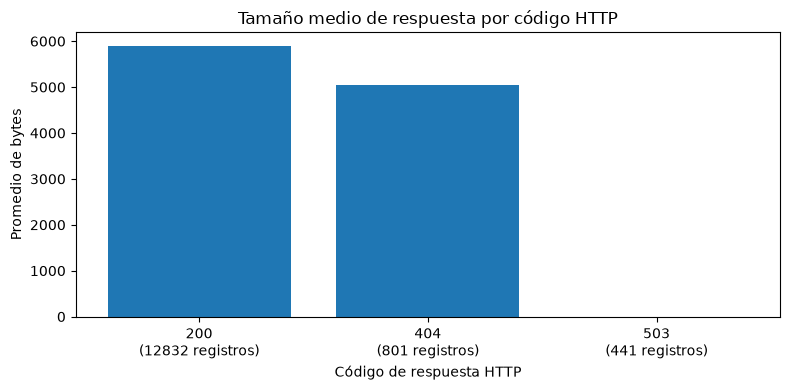

In [4]:
if resultado is not None:
    grupos = resultado["aggregations"]["por_codigo"]["buckets"]
    grupos_con_promedio = [
        grupo for grupo in grupos if grupo["promedio_bytes"]["value"] is not None
    ]
    if not grupos_con_promedio:
        print("No hay grupos con valores de bytes para calcular un promedio.")
    else:
        etiquetas = [f'{grupo["key"]}\n({grupo["doc_count"]} registros)'
                     for grupo in grupos_con_promedio]
        promedios = [grupo["promedio_bytes"]["value"] for grupo in grupos_con_promedio]
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.bar(range(len(promedios)), promedios)
        ax.set_xticks(range(len(promedios)), etiquetas)
        ax.set(xlabel="Código de respuesta HTTP", ylabel="Promedio de bytes",
               title="Tamaño medio de respuesta por código HTTP")
        fig.tight_layout()
        plt.show()

## 5. Experimento: Estrategias de ejecución de agregaciones y *Schema-on-Read*

### Pregunta e hipótesis
* **Pregunta:** Al agrupar registros web por código de respuesta HTTP y calcular el promedio de `bytes` (`terms` + `avg`), ¿cómo impacta la estrategia interna de ejecución de Elasticsearch en la latencia y el tiempo de cómputo del motor?
* **Hipótesis:**
  1. Activar la caché de peticiones de shard (`request_cache=true`) logrará la menor latencia al evitar recalcular los grupos en consultas repetidas con `size: 0`.
  2. Sin caché, las estrategias apoyadas en `doc_values` preindexados (`global_ordinals` y `map`) serán considerablemente más rápidas que un campo virtual calculado en tiempo de consulta (`runtime_mappings` / *schema-on-read*), ya que este último debe leer `_source` y ejecutar un script Painless registro por registro.

### Diseño experimental
* **Variable modificada (independiente):** Estrategia de ejecución en 4 configuraciones de solo lectura:
  1. **Caché de shard (`request_cache=true`)** sobre `response.keyword` (`doc_values`).
  2. **Estándar sin caché (`execution_hint: "global_ordinals"`)** sobre `response.keyword` (`doc_values`).
  3. **Tabla hash directa sin caché (`execution_hint: "map"`)** sobre `response.keyword` (`doc_values`).
  4. **Schema-on-read sin caché (`runtime_mappings`)** calculando el código HTTP al vuelo desde `_source` mediante Painless.
* **Variables medidas (dependientes):** Latencia total mediana en milisegundos (20 repeticiones tras 3 ejecuciones de calentamiento), `took` promedio reportado por Elasticsearch y tiempo interno puro de la agregación en microsegundos (`µs`) mediante la **Profile API** (`"profile": true`).
* **Variables fijas (control):** Índice `kibana_sample_data_logs`, cálculo exacto (`terms` + `avg` sobre `bytes`), `size: 0`, límite de 5 grupos y mismo contenedor Docker (`single-node`, 1 GB RAM).

> **Referencia para Dev Tools (ejemplo de configuración 4 con Profile API):**
> ```http
> GET kibana_sample_data_logs/_search?request_cache=false
> {
>   "size": 0,
>   "profile": true,
>   "runtime_mappings": {
>     "response_runtime": {
>       "type": "keyword",
>       "script": {
>         "source": "def v = params._source['response']; if (v != null) { emit(v.toString()); }"
>       }
>     }
>   },
>   "aggs": {
>     "por_codigo": {
>       "terms": { "field": "response_runtime", "size": 5 },
>       "aggs": { "promedio_bytes": { "avg": { "field": "bytes" } } }
>     }
>   }
> }
> ```

In [5]:
import statistics
import time

REPETICIONES = 20
CALENTAMIENTO = 3
campo_origen = campo_grupo.split(".")[0]  # "response" en _source


def ejecutar_peticion(cuerpo_dict, usar_cache=False):
    cache_flag = "true" if usar_cache else "false"
    url_exp = f"{url_elasticsearch.rstrip('/')}/{indice}/_search?request_cache={cache_flag}"
    payload = json.dumps(cuerpo_dict, ensure_ascii=False).encode("utf-8")
    req = Request(
        url_exp,
        data=payload,
        headers={"Content-Type": "application/json"},
        method="GET",
    )
    t0 = time.perf_counter()
    with urlopen(req, timeout=30) as resp:
        data = json.load(resp)
    latencia_ms = (time.perf_counter() - t0) * 1000.0
    return data, latencia_ms


def extraer_profile_us(res):
    total_nanos = 0
    for shard in res.get("profile", {}).get("shards", []):
        for agg in shard.get("aggregations", []):
            total_nanos += agg.get("time_in_nanos", 0)
    return total_nanos / 1000.0  # nanosegundos -> microsegundos


configuraciones = [
    {
        "nombre": "1. Caché activa\n(request_cache=true)",
        "usar_cache": True,
        "perfilable": False,  # profile=true deshabilita request_cache
        "cuerpo": {
            "size": 0,
            "aggs": {
                "por_codigo": {
                    "terms": {"field": campo_grupo, "size": limite_grupos},
                    "aggs": {"promedio_bytes": {"avg": {"field": campo_promedio}}},
                }
            },
        },
    },
    {
        "nombre": "2. Estándar\n(global_ordinals)",
        "usar_cache": False,
        "perfilable": True,
        "cuerpo": {
            "size": 0,
            "aggs": {
                "por_codigo": {
                    "terms": {
                        "field": campo_grupo,
                        "size": limite_grupos,
                        "execution_hint": "global_ordinals",
                    },
                    "aggs": {"promedio_bytes": {"avg": {"field": campo_promedio}}},
                }
            },
        },
    },
    {
        "nombre": "3. Hash directo\n(execution_hint=map)",
        "usar_cache": False,
        "perfilable": True,
        "cuerpo": {
            "size": 0,
            "aggs": {
                "por_codigo": {
                    "terms": {
                        "field": campo_grupo,
                        "size": limite_grupos,
                        "execution_hint": "map",
                    },
                    "aggs": {"promedio_bytes": {"avg": {"field": campo_promedio}}},
                }
            },
        },
    },
    {
        "nombre": "4. Schema-on-read\n(runtime_mappings)",
        "usar_cache": False,
        "perfilable": True,
        "cuerpo": {
            "size": 0,
            "runtime_mappings": {
                "grupo_runtime": {
                    "type": "keyword",
                    "script": {
                        "source": (
                            f"def v = params._source['{campo_origen}']; "
                            "if (v != null) { emit(v.toString()); }"
                        )
                    },
                }
            },
            "aggs": {
                "por_codigo": {
                    "terms": {"field": "grupo_runtime", "size": limite_grupos},
                    "aggs": {"promedio_bytes": {"avg": {"field": campo_promedio}}},
                }
            },
        },
    },
]

resultados_exp = []

try:
    for cfg in configuraciones:
        # Calentamiento para estabilizar cachés del sistema operativo y JIT
        for _ in range(CALENTAMIENTO):
            ejecutar_peticion(cfg["cuerpo"], usar_cache=cfg["usar_cache"])

        latencias = []
        tooks = []
        ultimo_res = None
        for _ in range(REPETICIONES):
            ultimo_res, lat_ms = ejecutar_peticion(cfg["cuerpo"], usar_cache=cfg["usar_cache"])
            latencias.append(lat_ms)
            tooks.append(ultimo_res["took"])

        # Verificar que todas las configuraciones devuelven exactamente los mismos promedios
        buckets = ultimo_res["aggregations"]["por_codigo"]["buckets"]
        resumen_grupos = {
            b["key"]: round(b["promedio_bytes"]["value"], 2)
            for b in buckets
            if b["promedio_bytes"]["value"] is not None
        }

        profile_us = None
        if cfg["perfilable"]:
            cuerpo_prof = dict(cfg["cuerpo"], profile=True)
            tiempos_prof = []
            for _ in range(REPETICIONES):
                res_p, _ = ejecutar_peticion(cuerpo_prof, usar_cache=False)
                tiempos_prof.append(extraer_profile_us(res_p))
            profile_us = statistics.median(tiempos_prof)

        resultados_exp.append(
            {
                "nombre": cfg["nombre"],
                "mediana_ms": statistics.median(latencias),
                "promedio_ms": statistics.mean(latencias),
                "took_prom_ms": statistics.mean(tooks),
                "profile_us": profile_us,
                "grupos": resumen_grupos,
            }
        )

    # Tabla resumen de mediciones
    print(f"{'Configuración':<38} | {'Mediana (ms)':>12} | {'ES took (ms)':>12} | {'Profile agg (µs)':>16}")
    print("-" * 88)
    for r in resultados_exp:
        etiqueta = r["nombre"].replace("\n", " ")
        prof_str = f"{r['profile_us']:.1f}" if r["profile_us"] is not None else "N/A (caché)"
        print(f"{etiqueta:<38} | {r['mediana_ms']:>12.2f} | {r['took_prom_ms']:>12.2f} | {prof_str:>16}")

    # Validación de equivalencia funcional
    referencia = resultados_exp[0]["grupos"]
    iguales = all(r["grupos"] == referencia for r in resultados_exp)
    print(f"\n¿Todas las estrategias entregaron exactamente los mismos grupos y promedios? {'Sí' if iguales else 'No'}")
    print(f"Promedios verificados (bytes): {referencia}")

except HTTPError as error:
    print(f"Elasticsearch respondió con el código HTTP {error.code}. Revisa que el índice {indice} exista.")
except (URLError, TimeoutError):
    print("No se pudo conectar con Elasticsearch. Revisa la URL y el estado del servicio.")

Configuración                          | Mediana (ms) | ES took (ms) | Profile agg (µs)
----------------------------------------------------------------------------------------
1. Caché activa (request_cache=true)   |         3.28 |         1.05 |      N/A (caché)
2. Estándar (global_ordinals)          |         3.72 |         1.05 |           1145.6
3. Hash directo (execution_hint=map)   |         5.72 |         2.50 |           2074.2
4. Schema-on-read (runtime_mappings)   |        94.02 |        91.75 |          93962.4

¿Todas las estrategias entregaron exactamente los mismos grupos y promedios? Sí
Promedios verificados (bytes): {'200': 5897.85, '404': 5049.24, '503': 0.0}


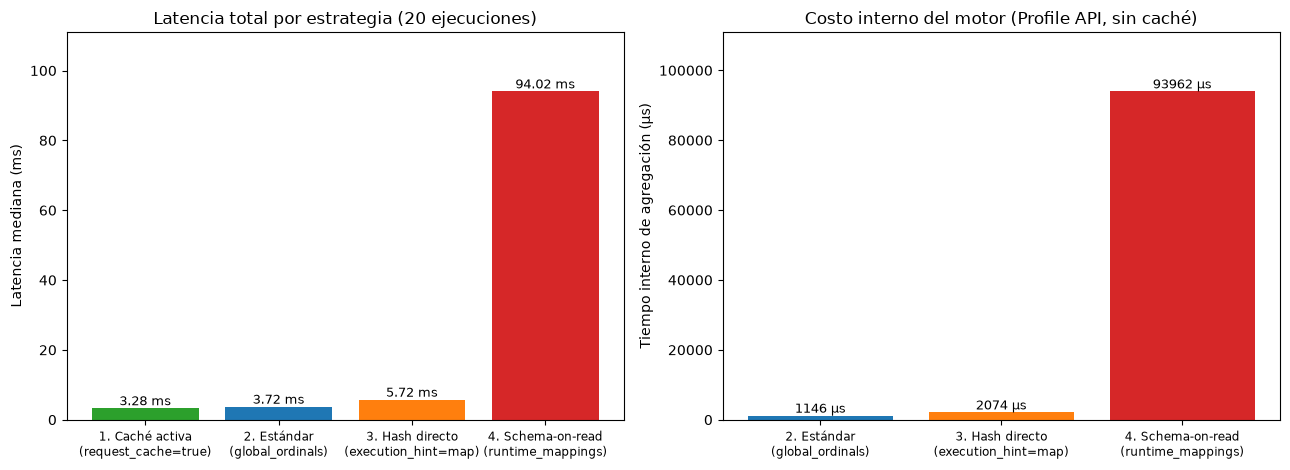

In [6]:
if resultados_exp:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

    # Gráfico 1: Latencia total extremo a extremo (mediana de 20 ejecuciones)
    nombres_1 = [r["nombre"] for r in resultados_exp]
    valores_1 = [r["mediana_ms"] for r in resultados_exp]
    barras_1 = ax1.bar(
        range(len(valores_1)),
        valores_1,
        color=["#2ca02c", "#1f77b4", "#ff7f0e", "#d62728"],
    )
    ax1.set_xticks(range(len(valores_1)), nombres_1, fontsize=8.5)
    ax1.set_ylabel("Latencia mediana (ms)")
    ax1.set_title(f"Latencia total por estrategia ({REPETICIONES} ejecuciones)")
    ax1.set_ylim(0, max(valores_1) * 1.18)
    for bar, val in zip(barras_1, valores_1):
        ax1.text(
            bar.get_x() + bar.get_width() / 2,
            val,
            f"{val:.2f} ms",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    # Gráfico 2: Tiempo interno de la agregación en Elasticsearch (Profile API)
    perfilados = [r for r in resultados_exp if r["profile_us"] is not None]
    nombres_2 = [r["nombre"] for r in perfilados]
    valores_2 = [r["profile_us"] for r in perfilados]
    barras_2 = ax2.bar(
        range(len(valores_2)),
        valores_2,
        color=["#1f77b4", "#ff7f0e", "#d62728"],
    )
    ax2.set_xticks(range(len(valores_2)), nombres_2, fontsize=8.5)
    ax2.set_ylabel("Tiempo interno de agregación (µs)")
    ax2.set_title("Costo interno del motor (Profile API, sin caché)")
    ax2.set_ylim(0, max(valores_2) * 1.18)
    for bar, val in zip(barras_2, valores_2):
        ax2.text(
            bar.get_x() + bar.get_width() / 2,
            val,
            f"{val:.0f} µs",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    fig.tight_layout()
    plt.show()

## 6. Conclusión y escalabilidad

### Análisis de resultados
Las cuatro configuraciones produjeron exactamente los mismos grupos HTTP y promedios de `bytes`, pero con diferencias marcadas en el tiempo de ejecución debido a cómo opera internamente Elasticsearch sobre Lucene:

* **Por qué `global_ordinals` y `map` son rápidos sin caché:** Ambos leen **`doc_values`**, una estructura columnar precalculada en disco (aprovechando la caché de páginas del sistema operativo) que evita abrir el documento JSON completo. `global_ordinals` mapea cada valor a un entero compacto para agrupar con arreglos ligeros, mientras que `map` agrupa directamente los valores en una tabla hash en memoria. En campos de baja cardinalidad como `response.keyword` (3 códigos HTTP) su rendimiento es cercano.
* **Por qué `request_cache=true` obtiene la menor latencia:** Al incluir `"size": 0` y no modificarse los segmentos del índice, Elasticsearch almacena en caché el resultado de la agregación a nivel de **shard**, evitando re-recorrer los documentos en consultas repetitivas (clave en dashboards de monitoreo).
* **Por qué `runtime_mappings` incrementa el costo de CPU y latencia:** Al operar bajo *schema-on-read* sin `doc_values` preindexados, el motor debe descomprimir y leer el campo `_source` de cada documento y ejecutar el script Painless en tiempo de consulta. A cambio, permite crear agrupaciones nuevas sin reindexar ni ocupar espacio adicional en disco.

### Justificación de la muestra y proyección de escalabilidad
El experimento se ejecutó sobre la muestra `kibana_sample_data_logs` (~14.000 registros) debido a las restricciones de hardware del entorno local (contenedor Docker `single-node` limitado a `1 GB` de RAM). Al escalar a **10 millones de registros (> 1 GB)**:
* El costo de `runtime_mappings` crecería de manera lineal con el volumen de documentos escaneados, pasando de decenas de milisegundos a varios segundos si no se acota primero con un filtro estricto (por ejemplo, un rango acotado de `@timestamp`).
* Las agregaciones sobre `doc_values` (`global_ordinals`) escalan horizontalmente dividiendo el índice en múltiples **shards primarios** distribuidos en varios nodos de datos: cada shard agrega localmente sus registros en paralelo y el nodo coordinador realiza la fase *reduce* final, mientras `request_cache` absorbe consultas recurrentes en tiempo real.